# Iris regression with a small neural network

Predict **petal width** (cm) from the other three measurements: sepal length, sepal width and petal length.

Network: **3 inputs → hidden layer(s) → 1 output** (linear), ReLU activations, trained with Adam on squared error.
A plain linear regression serves as a baseline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Settings

Use `(16,)` for one hidden layer or `(16, 8)` for two.

In [2]:
HIDDEN_LAYERS = (16, 8)   # two hidden layers: 16 and 8 neurons
SEED = 42

## Data

Columns 0–2 (sepal length, sepal width, petal length) are the inputs; column 3 (petal width) is the target.
The split is stratified by species so all three are represented in both sets.

In [3]:
iris = load_iris()
X = iris.data[:, :3]
y = iris.data[:, 3]
feature_names = iris.feature_names[:3]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=iris.target, random_state=SEED
)
print("Inputs:", feature_names)
print(f"Train: {X_train.shape[0]} samples, test: {X_test.shape[0]} samples")

Inputs: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']
Train: 105 samples, test: 45 samples


## Models

Both models see standardized inputs. The neural network uses a linear output unit and minimizes squared error;
a little L2 regularization (`alpha`) keeps the weights small.

In [4]:
mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=HIDDEN_LAYERS,
        activation="relu",
        solver="adam",
        learning_rate_init=0.01,
        alpha=1e-3,
        max_iter=2000,
        random_state=SEED,
    ),
)
linear = make_pipeline(StandardScaler(), LinearRegression())

mlp.fit(X_train, y_train)
linear.fit(X_train, y_train)
print("Both models trained.")

Both models trained.


## Evaluation

RMSE is in centimetres; R² is the fraction of variance in petal width explained.

In [5]:
def report(name, model):
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
    rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))
    print(f"{name:<18} train RMSE {rmse_train:.3f}  test RMSE {rmse_test:.3f}  "
          f"test R² {r2_score(y_test, pred_test):.3f}")
    return pred_test

print(f"Target range: {y.min():.1f}–{y.max():.1f} cm, std {y.std():.3f} cm\n")
pred_mlp = report(f"MLP {HIDDEN_LAYERS}", mlp)
pred_lin = report("Linear regression", linear)

Target range: 0.1–2.5 cm, std 0.760 cm

MLP (16, 8)        train RMSE 0.182  test RMSE 0.206  test R² 0.920
Linear regression  train RMSE 0.185  test RMSE 0.203  test R² 0.922


## Predicted vs. actual

Points on the dashed line are perfect predictions. Colours show species.

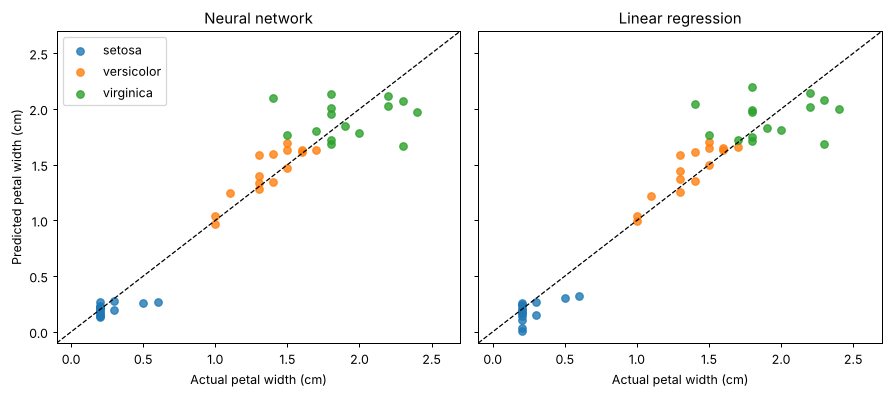

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
_, _, _, species_test = train_test_split(
    X, iris.target, test_size=0.3, stratify=iris.target, random_state=SEED
)
lims = [y.min() - 0.2, y.max() + 0.2]
for ax, pred, title in [(axes[0], pred_mlp, "Neural network"), (axes[1], pred_lin, "Linear regression")]:
    for k, name in enumerate(iris.target_names):
        m = species_test == k
        ax.scatter(y_test[m], pred[m], label=name, alpha=0.8)
    ax.plot(lims, lims, "k--", lw=1)
    ax.set(xlim=lims, ylim=lims, xlabel="Actual petal width (cm)", title=title)
axes[0].set_ylabel("Predicted petal width (cm)")
axes[0].legend()
plt.tight_layout()
plt.show()

## Takeaways

- Petal width is almost a linear function of petal length, so the linear baseline does about as well as the network.
  A neural network is not automatically better when the underlying relationship is simple.
- Most of the error comes from scatter within each species rather than a systematic bias.
- Things to try: switch to one hidden layer, change `SEED` to see run-to-run variation, add species as a one-hot input,
  or predict sepal length instead (a noisier target).